# Synthetic Data Generation using TVAE

This notebook implements a TVAE (Tabular Variational Autoencoder) model to generate synthetic data.

The objective is to compare TVAE with CTGAN in terms of:
- Data quality
- Preservation of statistical properties
- Fairness across sensitive attributes

TVAE represents a probabilistic generative approach, in contrast to the adversarial training used in CTGAN.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ctgan import TVAE

## Dataset

We use the Adult Income dataset which is our test data.

In [2]:
df = pd.read_csv("test_data/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data Preprocessing

We define categorical variables and clean the dataset.

In [3]:
df = df.dropna()

categorical_columns = [
    'workclass', 'education', 'marital-status',
    'occupation', 'relationship', 'race',
    'sex', 'native-country', 'income'
]

## TVAE Model Training

TVAE learns a latent representation of the data and reconstructs it through a decoder network.

Unlike CTGAN, TVAE optimizes a probabilistic objective rather than using adversarial training.

In [4]:
model = TVAE(
    epochs=200,
    verbose=True
)

model.fit(df, discrete_columns=categorical_columns)

Loss: 4.885:  14%|█▍        | 28/200 [03:25<16:05,  5.61s/it] 

## Synthetic Data Generation

In [5]:
synthetic_data = model.sample(5000)

synthetic_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,45,Private,116547,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,-11,0,40,United-States,>50K
1,60,Private,73035,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,-13,0,40,United-States,<=50K
2,36,Private,126452,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,-14,0,40,United-States,<=50K
3,58,Private,126581,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,-10,-1,40,United-States,<=50K
4,37,Private,128400,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,-1,0,40,United-States,>50K


## Distribution Comparison

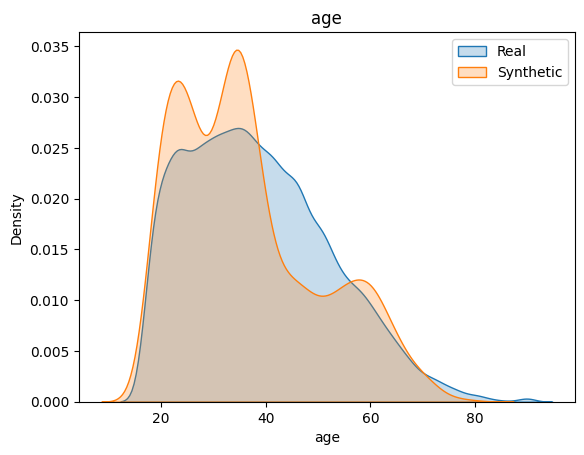

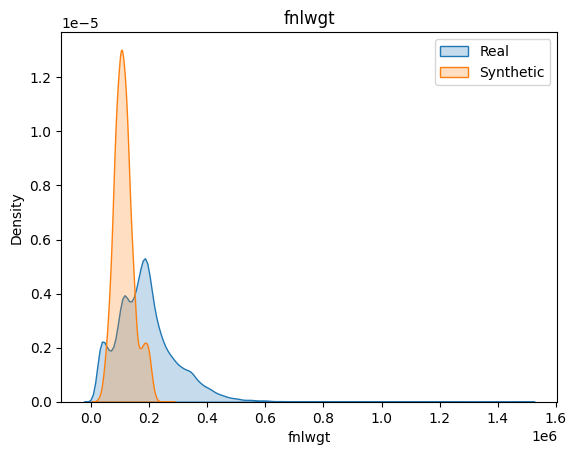

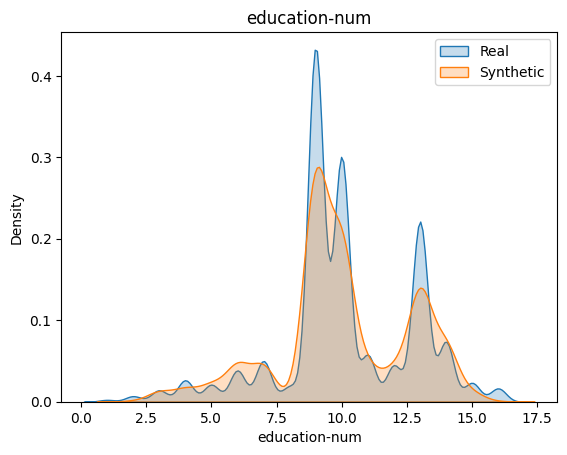

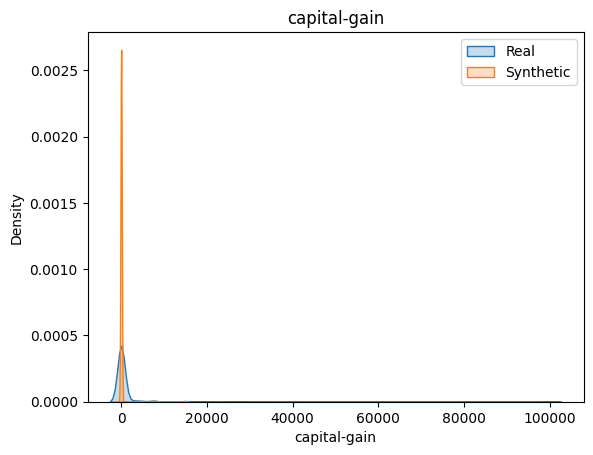

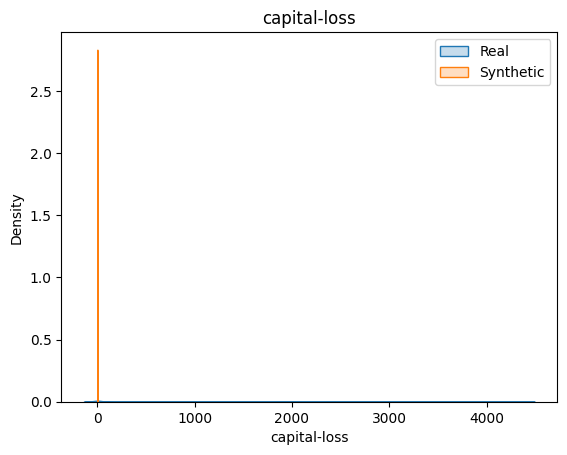

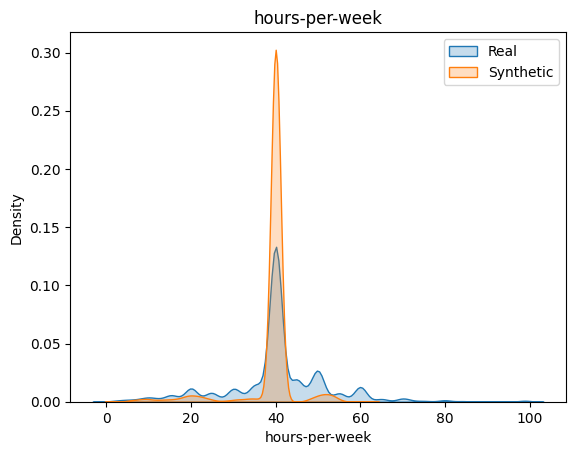

In [6]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    plt.figure()
    sns.kdeplot(df[col], label="Real", fill=True)
    sns.kdeplot(synthetic_data[col], label="Synthetic", fill=True)
    plt.title(col)
    plt.legend()
    plt.show()

## Fairness Evaluation

In [7]:
#Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
synthetic_data['income_binary'] = synthetic_data['income'].apply(lambda x: 1 if '>50K' in x else 0)

In [8]:
#Statistical Parity
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.085149
Male      0.297274
Name: income_binary, dtype: float64


In [9]:
#Disparity Gap
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.085149
Male      0.297274
Name: income_binary, dtype: float64
